In [2]:
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.stats import norm
import random


## GBM:

$dS_t​=μS_t​dt+σS_t​dW_t​$


Euler Discretization - SImplest approach: Over small interval, 

$S_t≈S_{t+Δt}$

So $ΔS≈μS_t​Δt+σS_t​ΔW.$

Since $ΔW=\sqrt{Δt​}Z,$

#### We get $S_{t+Δt} = S_t + μS_tΔt + σS_t\sqrt{Δt​}Z$

However, between time t and t+Δt , S isn't constant.
We can solve the GBM SDE directly, which is a long and d=tedious process.

In the end you will get this: 


### $S_{t+Δt}​=S_t ​exp[(μ−\frac{σ^2​}{2})Δt+σΔtZ]$

In [5]:
class StochasticProcess:
    def __init__(self, drift, volatility, delta_t, initial_asset_price):
        self.drift = drift
        self.volatility = volatility
        self.delta_t = delta_t
        self.asset_prices = [initial_asset_price]
        self.current_asset_price = initial_asset_price

    def time_step_euler(self):
        dW = np.random.normal(0, math.sqrt(self.delta_t))
        dS = self.drift * self.delta_t * self.current_asset_price + self.volatility * self.current_asset_price * dW
        self.asset_prices.append(self.current_asset_price + dS)
        self.current_asset_price = self.current_asset_price + dS

    def time_step_exact(self):
        z = np.random.normal()

        self.current_asset_price *= math.exp(
            (self.drift - 0.5 * self.volatility**2) * self.delta_t
            + self.volatility * math.sqrt(self.delta_t) * z
        )

        self.asset_prices.append(self.current_asset_price)


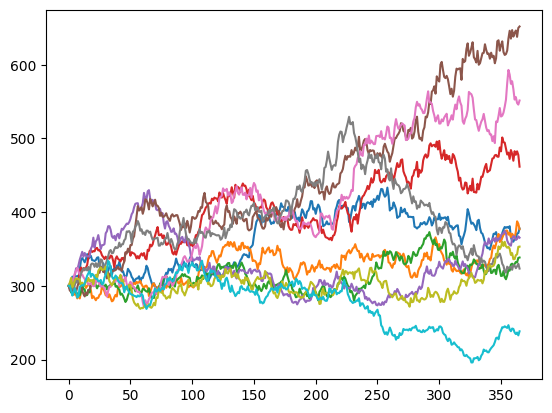

In [9]:
processes = []
for i in range(0,100):
    processes.append(StochasticProcess(.2,.3,1/365,300))


for process in processes:
    tte = 1
    while(tte - process.delta_t) > 0:
        process.time_step_exact()
        tte = tte - process.delta_t
        
for p in random.sample(processes,10):
    plt.plot(p.asset_prices)

## Option Pricing with Black-Scholes:

Risk-Neutral Pricing (Asst Pricing Theory) :

In the absence of arbitrage,there is a risk-neutral measure Q, with the underlying's price being a martingale (sequence of random prices)

Then the price of a european call option is:

$C(S_0, K, T) = e^{-rT}E^Q[max(S_T - K, 0)] $

it is equal to the risk-neutral expected payoff.

SInce we don't know the future price, we can only find the expected value of today.


Solving the expectation is a very long and complicated process. In the end, you'll get a Black-Scholes PDE and solving this PDE yields:


### $C(S_0,K,T) = S_0N(d_1)-Ke^{-rT}N(d_2)$

Where:

$d_1=\frac{\ln(S_0/K)+(r+\frac12\sigma^2)T}{\sigma\sqrt{T}}$

and

$d_2=d_1-\sigma\sqrt{T}$

Monte Carlo Equation:

$C=e^{−rT}\frac{1}{N}​\sum^{N}_{i=1}​max(S_{T}^{(i)}​−K,0)​$

In [4]:

def black_scholes_call(current_asset_price, call_strike, tte, rfr, volatility):
    d1 = (
        np.log(current_asset_price / call_strike)
        + (rfr + 0.5 * volatility**2) * tte
    ) / (volatility * np.sqrt(tte))

    d2 = d1 - volatility * np.sqrt(tte)

    call_price = (
        current_asset_price * norm.cdf(d1)
        - call_strike * np.exp(-rfr * tte) * norm.cdf(d2)
    )
    return call_price

In [5]:
print(black_scholes_call(7656.98,200, 6/365 ,.0478, 12.5166))

7463.217141914577


In [6]:
class EuroCallMonteCarloSim:
    def __init__(self, call_strike, n_options, initial_asset_price, drift, delta_t, volatility, tte, rfr):
        self.stochastic_processes = []
        for i in range(0, n_options):
            self.stochastic_processes.append(StochasticProcess(drift, volatility, delta_t, initial_asset_price))
        for stochastic_process in self.stochastic_processes:
            ttei = tte
            while ((ttei - stochastic_process.delta_t) > 0):
                ttei = ttei - stochastic_process.delta_t
                stochastic_process.time_step_euler()

        payoffs = []
        self.final_prices = []
        self.payoffs_avg = []
        for stochastic_process in self.stochastic_processes:
            final_price = stochastic_process.asset_prices[len(stochastic_process.asset_prices)-1]
            self.final_prices.append(final_price)

            payoff = final_price - call_strike
            z = payoff if payoff > 0 else 0
            payoffs.append(z)
            if len(payoffs) > 0:
                self.payoffs_avg.append(np.average(payoffs))

        self.price = np.average(payoffs) * math.exp(-rfr * tte)


In [7]:
print(EuroCallMonteCarloSim(200, 2000,7656.98, .0478, 1/365,  12.5166, 6/365, .0478).price)

8085.64542889241


Current Stock price:  365.44
Strike Price:  200
Time to maturity (in years) 370/365
Risk free rate:  .0478
Volatility:  0.9375


Stock Price:  365.44
STrike price:  200.0
TIme to Expiration:  1.0136986301369864
Risk-free rate:  0.0478
Volatility 0.9375


C:\Users\vflip\AppData\Local\Temp\ipykernel_7656\1851888073.py:61: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ro" (-> color='r'). The keyword argument will take precedence.
  axes[1][0].plot(stock_price, bs_price ,"ro", color="green", label="Black-Scholes Price")


BS Option Price:  208.91223208882258
MC Option Price:  206.1572795354891


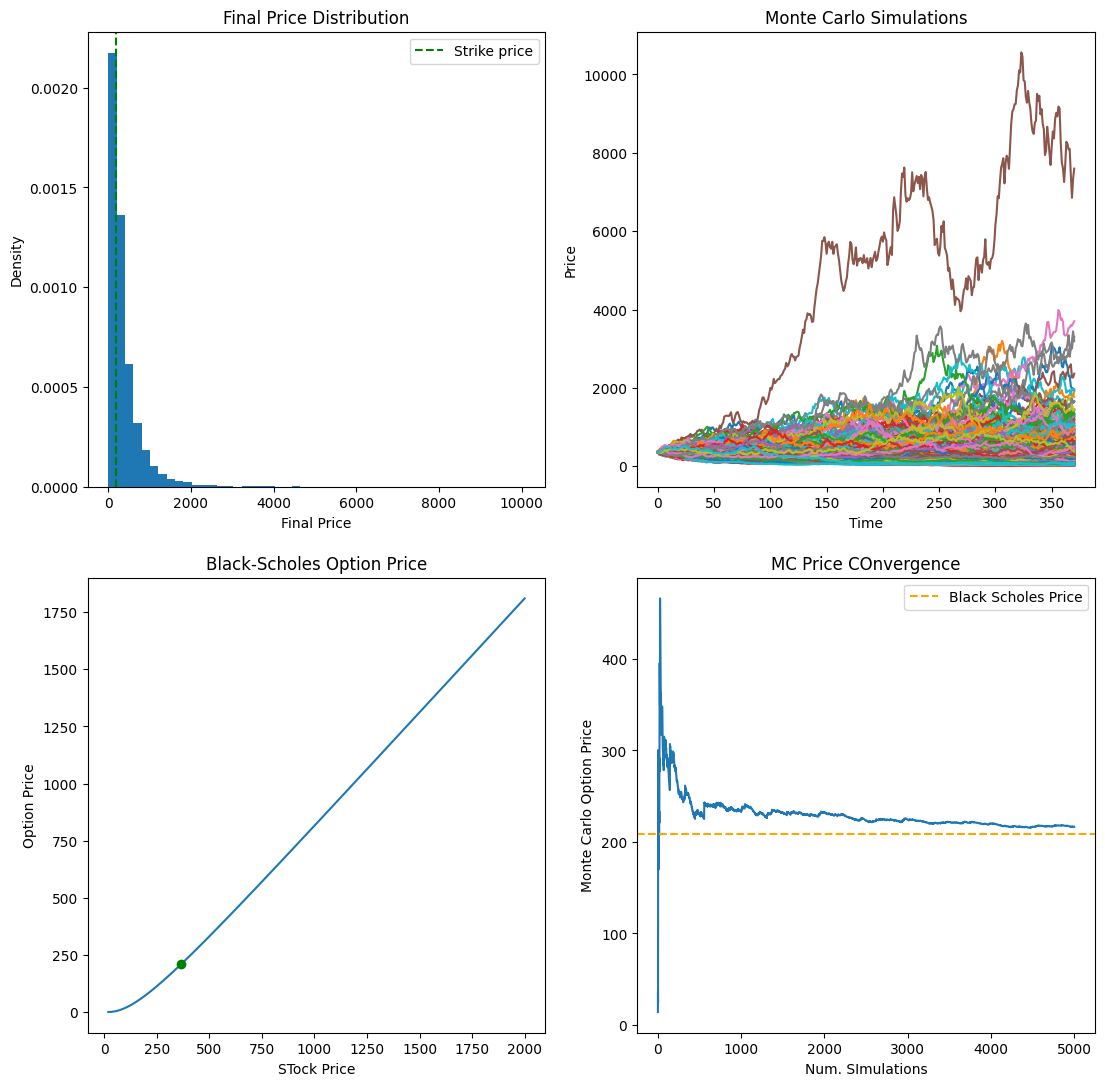

In [10]:
stock_price = float(input("Current Stock price: "))
strike_price = float(input("Strike Price: "))
tte = float(Fraction(input("Time to maturity (in years)")))
rfr = float(input("Risk free rate: "))
sigma = float(input("Volatility: "))

print("Stock Price: ", stock_price)
print("STrike price: ", strike_price)
print("TIme to Expiration: ",  tte)
print("Risk-free rate: ", rfr)
print("Volatility", sigma)

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(13,13)
)

test = EuroCallMonteCarloSim(
    strike_price,
    5000,
    stock_price,
    rfr,
    1/365,
    sigma,
    tte,
    rfr
)

# Final price distribution
axes[0][0].hist(
    test.final_prices,
    bins=50,
    density=True
)
axes[0][0].set_ylabel("Density")
axes[0][0].set_xlabel("Final Price")
axes[0][0].set_title("Final Price Distribution")

axes[0][0].axvline(
    strike_price,
    color="green",
    linestyle="--",
    label="Strike price"
)
axes[0][0].legend()

# Monte Carlo SIms
for s in test.stochastic_processes[:500]:
    axes[0][1].plot(s.asset_prices)
axes[0][1].set_ylabel("Price")
axes[0][1].set_xlabel("Time")
axes[0][1].set_title("Monte Carlo Simulations")

bs_price = black_scholes_call(stock_price, strike_price, tte, rfr, sigma)

#Black Scholes Plot
x = np.linspace(strike_price*0.1, strike_price*10, 1000)
y = black_scholes_call(x, strike_price, tte, rfr, sigma)
axes[1][0].plot(x, y)
axes[1][0].plot(stock_price, bs_price ,"ro", color="green", label="Black-Scholes Price")
#axes[1][0].plot(stock_price, test.price ,"ro", color="red", label="Monte Carlo Price")
axes[1][0].set_xlabel("STock Price")
axes[1][0].set_ylabel("Option Price")
axes[1][0].set_title("Black-Scholes Option Price")
#axes[1][0].legend()


#MC COnvergence:
axes[1][1].plot(test.payoffs_avg)
axes[1][1].set_xlabel("Num. SImulations")
axes[1][1].set_ylabel("Monte Carlo Option Price")
axes[1][1].set_title("MC Price COnvergence")
axes[1][1].axhline(bs_price, label="Black Scholes Price",linestyle="--", color="orange")
axes[1][1].legend()

print("BS Option Price: ", bs_price)
print("MC Option Price: ", test.price)

plt.show()